<a href="https://colab.research.google.com/github/Miller12567/5201_Intro_to_Siesmology/blob/main/5201_Lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Introduction to Seismology
Earth 5201
Homework 2
Due Friday October 9, 2026

**Problem (1)** Using the normal mode example in Lecture 6, plot the sum of the first 40 modes at t=1.5, 5, and 10.

The length of the string is 20, the velocity is 3, and the location of the source xs=8. For the x-axis, discretize this into units of length 0.1.

Use the same expression for F(ω_n) and the normal mode summation on slide 26 (the number in the lower corner of Lecture 6).

**Use 1 for the value of tau in the F(ω_n) equation.**

The time slice at 1.5 seconds should be identical to the figure on slide 27, but what are the changes at 5 and 10
seconds that you observe?

In [ ]:
%pip install obspy -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 76.8 MB/s eta 0:00:00


In [144]:
import numpy as np
import matplotlib.pylab as plt
import obspy.taup
from obspy.taup import TauPyModel

Text(0.5, 1.0, 'Sum of First 40 modes @ t = 1.5, 5, 10 (c=3, source=8, tau=1, Length=20)')

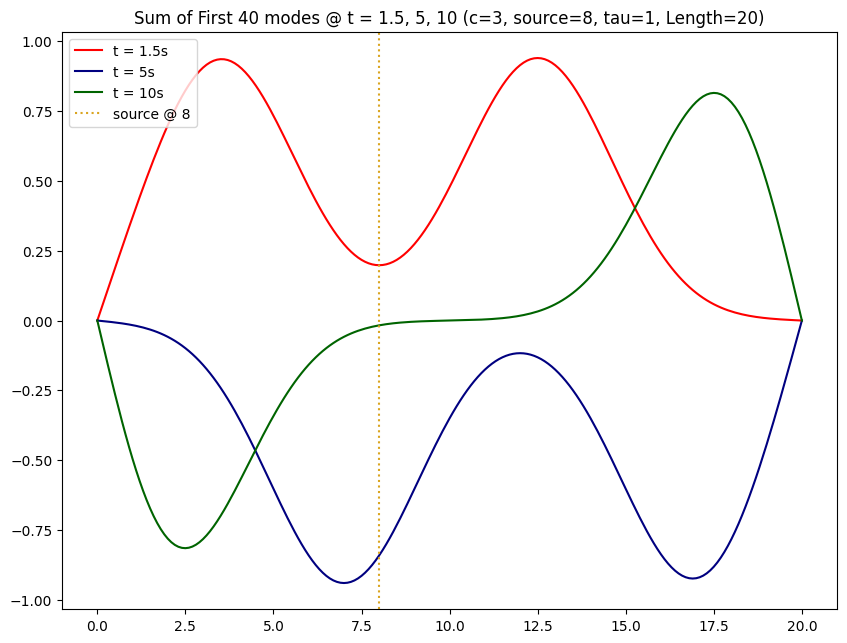

In [ ]:
x = np.linspace(0, 20, 201)

c = 3.0 # I assume this is in m/s
xs = 8.0
t = [1.5, 5, 10]
def mode_sum(x, xs, t, n_modes=40, tau_src=1.0, L=20.0, c=3.0):
    u = np.zeros_like(x)
    for n in range(1, n_modes + 1):
        wn = n * np.pi * c / L
        An = np.sin(n * np.pi * xs / L) * np.exp(-(wn * tau_src) ** 2 / 4)
        Un = np.sin(n * np.pi * x / L)
        u += An * Un * np.cos(wn * t)
    return u

mode_1_5 = mode_sum(x, xs, t[0])
mode_5 = mode_sum(x, xs, t[1])
mode_10 = mode_sum(x, xs, t[2])
plt.figure(figsize=(10,7.5))
plt.plot(x, mode_1_5, color='red',label='t = 1.5s')
plt.plot(x, mode_5, color='navy',label='t = 5s')
plt.plot(x, mode_10, color='darkgreen',label='t = 10s')
plt.axvline(xs, color="goldenrod", linestyle=":", label="source @ 8")
plt.legend(loc='upper left')
plt.title('Sum of First 40 modes @ t = 1.5, 5, 10 (c=3, source=8, tau=1, Length=20)')

The graph at 1.5 doesn't match the lecture slide , but thats because our simulation does not have the same parameters as the lecture so obviously it would not match. The diffrence with t = 5 & t = 10 is that there are some inversions, 2 with the 10s and 1 with the 5s. (but if we kept the parameters the same it would look different)

**Problem (2)** A downgoing P-wave in a medium with a P velocity of 6 km/s travels through
this “corner” shaped structure. If the incident ray is at an angle of 60o from the horizontal
and the final ray is at an angle of 75o from the vertical, what is the P velocity within the
corner shaped medium?

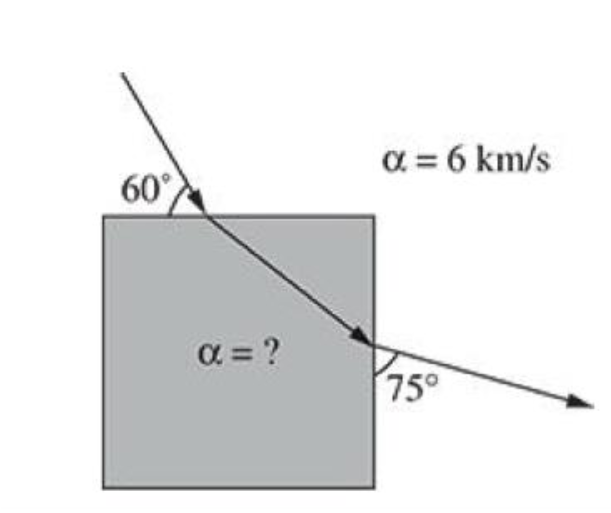

In [ ]:
#snell's law v2*sin(theta1)=v1*sin(theta_2)
# v1 = 6km/s
# theta 1 = 30deg = 90 - 60
# theta 3 = 15deg = 90 - 75
# sin(30) / 6 = sin(theta1) / v2
# cos(theta1)/v2 =  sin(15) / 6
# -> cos(theta2) / sin(30) = sin(15)/sin(theta2)
# -> tan(theta2) = sin(30) / sin(15)
theta2 = np.atan(np.sin( 30 * np.pi / 180) / np.sin( 15 * np.pi / 180))
theta2_deg = theta2 * 180 / np.pi

v2 = np.sin(theta2) * 6 / np.sin(30 * np.pi / 180 )

print(v2,'km/s')

10.656886007725385 km/s


**Problem (3a)** Using the obspy taup function, create a version of figure 4.19 using the ak135
velocity model with 0.1 degree grid spacing and a source depth of 40 km. A hint to extract
the travel time values, if you have:

arrivals=model.get_travel_times(source_depth_in_km=40,distance_in_degree=5)

Numarrivals = len(arrivals)

Arrivaltime = arrivals[0].time

You can loop over the number of arrivals and extract the arrival times in sequential order.
You will want to plot each theoretical arrival as a dot rather than a line

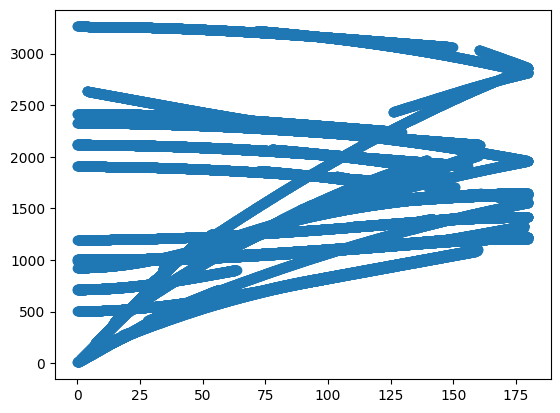

In [ ]:
model = TauPyModel(model="ak135")

arrivals=model.get_travel_times(source_depth_in_km=40,distance_in_degree=5)
Numarrivals = len(arrivals)
Arrivaltime = arrivals[0].time

distances = np.arange(0, 180, 0.1)

x_distances = []
y_times = []

for dist in distances:
    arrivals = model.get_travel_times(source_depth_in_km=40, distance_in_degree=dist)
    for arr in arrivals:
        x_distances.append(dist)
        y_times.append(arr.time)

plt.scatter(x_distances,y_times)

**3b)** Find a broadband station (HHZ) that is roughly 90 degrees away from an earthquake of
magnitude 7.5 out to 1 hour. Label any of the theoretical phase arrivals from taup on your
plot. You may need to play around with filtering to observe additional arrivals.

In [160]:
from obspy.clients.fdsn import Client
from obspy.geodetics import locations2degrees
from obspy import UTCDateTime

lat: -8.3358 long: 121.3446 t_0: 2026-08-14T21:58:21.561000Z
Trying station AF.ALKP (93.62°)...
Trying station AF.BLWY (89.68°)...
Trying station AF.CNG (85.57°)...
Trying station AF.CRLN (87.53°)...
Trying station AF.GETA (87.71°)...
Trying station AF.KIG (90.98°)...
Trying station AF.MOPA (86.64°)...
Trying station AF.MUSN (88.21°)...
Trying station AF.POGA (85.86°)...
Success! Data fetched for AF.POGA


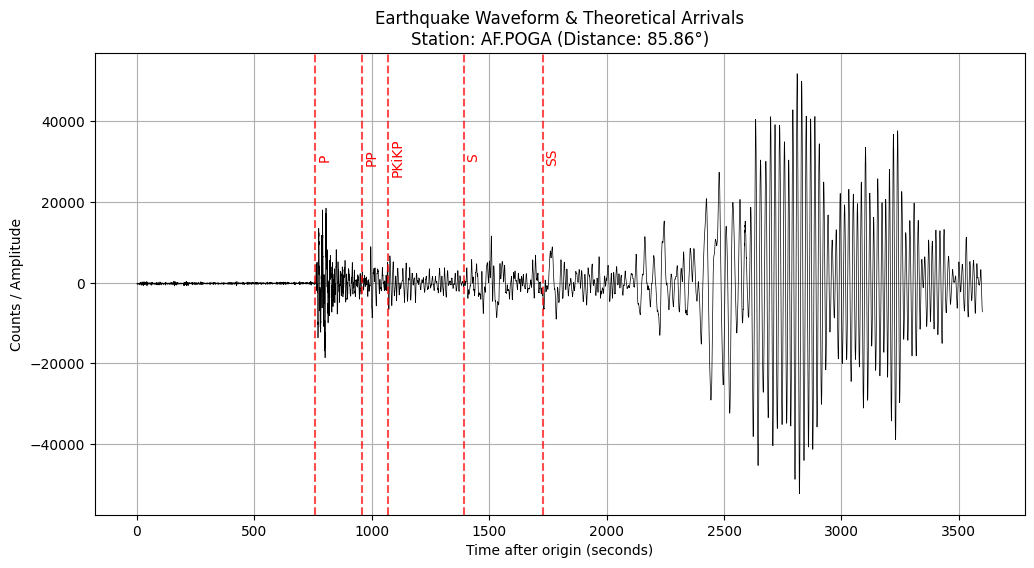

In [159]:
usgs = Client("USGS")
ES = Client("Earthscope")

event_usgs = usgs.get_events(minmagnitude=7.5, starttime="2020-01-01")
usgs1 = event_usgs[1]
usgs_origin = usgs1.origins[0]

usgslat = usgs_origin.latitude
usgslong = usgs_origin.longitude
t_0 = usgs_origin.time
print("lat:", usgslat, "long:", usgslong, "t_0:", t_0)

inventory = ES.get_stations(channel="HHZ", minlatitude=-30, maxlatitude=30, minlongitude=-80, maxlongitude=80, starttime=t_0, endtime=t_0 + 3600, level="station")
target_net = None
target_sta = None
target_dist = None

st = None

for net in inventory:
    for sta in net:
        # Check distance
        dist_deg = locations2degrees(
            usgslat, usgslong, sta.latitude, sta.longitude
        )

        if 85 <= dist_deg <= 95:
            try:
                print(
                    f"Trying station {net.code}.{sta.code} ({dist_deg:.2f}°)..."
                )
                st = ES.get_waveforms(
                    network=net.code,
                    station=sta.code,
                    location="*",
                    channel="HHZ",
                    starttime=t_0,
                    endtime=t_0 + 3600,
                )
                target_net = net.code
                target_sta = sta.code
                target_dist = dist_deg
                print(f"Success! Data fetched for {target_net}.{target_sta}")
                break
            except Exception as e:
                # If 204 or no data, keep trying next station
                continue
    if st is not None:
        break

st = ES.get_waveforms(
    network="AF",
    station="POGA",
    location="*",
    channel="HHZ",
    starttime=t_0,
    endtime=t_0 + 3600,
)

# Clean up waveform data (remove trend/dc offset)
st.detrend("demean")

# 2. Calculate phase arrivals using the dynamically found distance
model = TauPyModel(model="ak135")
arrivals = model.get_travel_times(
    source_depth_in_km=usgs1.origins[0].depth / 1000.0,
    distance_in_degree=target_dist, # Use variable here!
    phase_list=["P", "S", "PP", "SS", "PKiKP"],
)

tr = st[0]
times = tr.times()

plt.figure(figsize=(12, 6))
plt.plot(times, tr.data, color="black", lw=0.5, label=f"{target_net}.{target_sta} HHZ")

# Overlay phase arrival times
for arr in arrivals:
    plt.axvline(
        x=arr.time,
        color="red",
        linestyle="--",
        alpha=0.7,
        label=arr.name if arr.name not in plt.gca().get_legend_handles_labels()[1] else "",
    )
    plt.text(
        arr.time + 10,
        max(tr.data) * 0.6,
        arr.name,
        color="red",
        rotation=90,
        verticalalignment="center",
    )

plt.xlabel("Time after origin (seconds)")
plt.ylabel("Counts / Amplitude")
plt.title(
    f"Earthquake Waveform & Theoretical Arrivals\nStation: {target_net}.{target_sta} (Distance: {target_dist:.2f}°)"
)
plt.grid(True)
plt.show()


**3c)** Compute and plot the time difference between ak135 and PREM for only P wave arrivals between 6 and 90 degrees at 0.1 degree intervals from a source at 40 km. For this, you can append a phase_list tag to get_travel_times for something that looks like:

parrival = model.get_travel_times(source_depth_in_km=40,distance_in_degree=10,phase_list=["P"])

Furthermore, find the P wave depth curves for both PREM and AK135 and comment on the
differences between them and how they may relate to your travel time difference curve.

In [158]:
lin = np.linspace(6.0, 90.0, 841)

ak135 = TauPyModel(model="ak135")
PREMjamin_Franklin = TauPyModel(model="PREM")

p_arrival = ak135.get_travel_times(source_depth_in_km=40,distance_in_degree=10,phase_list=["P"])
p_time = p_arrival[0].time

pfarrival = PREMjamin_Franklin.get_travel_times(source_depth_in_km=40,distance_in_degree=10,phase_list=["P"])
pf_time = pfarrival[0].time

time_diffs = []

for d in lin:
    t_ak135 = ak135.get_travel_times(
        source_depth_in_km=40, distance_in_degree=d, phase_list=["P"]
    )[0].time
    t_prem = PREMjamin_Franklin.get_travel_times(
        source_depth_in_km=40, distance_in_degree=d, phase_list=["P"]
    )[0].time

    time_diffs.append(t_ak135 - t_prem)



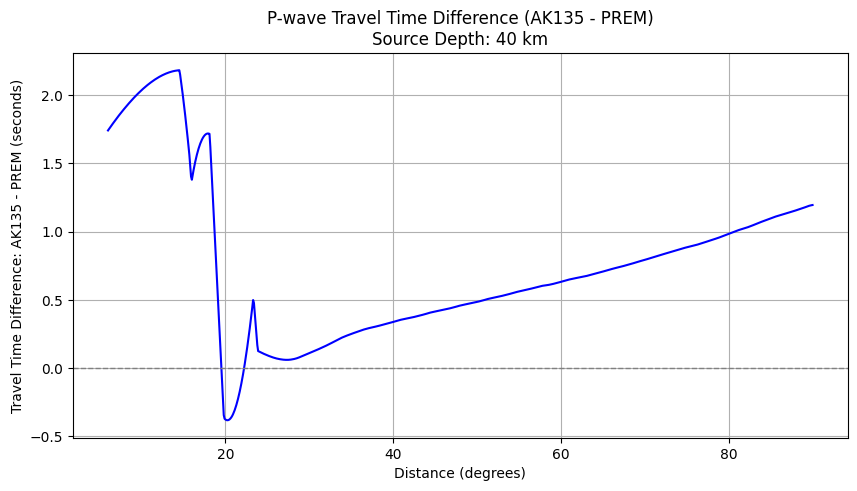

In [136]:
plt.figure(figsize=(10, 5))
plt.plot(lin, time_diffs, color="blue", lw=1.5)
# Axis labels and title
plt.xlabel("Distance (degrees)")
plt.ylabel("Travel Time Difference: AK135 - PREM (seconds)")
plt.title(
    "P-wave Travel Time Difference (AK135 - PREM)\nSource Depth: 40 km"
)

plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.grid(True)

plt.show()

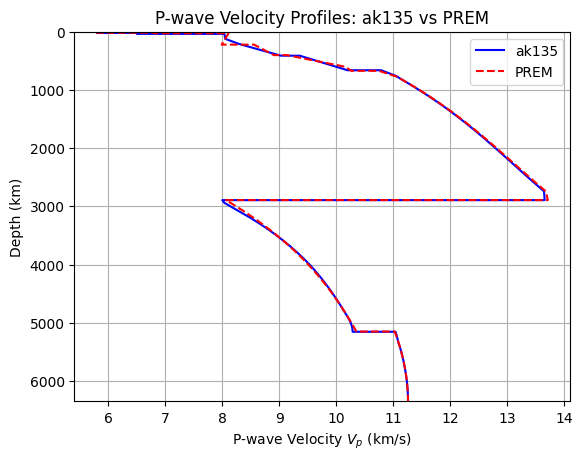

In [187]:
v_ak135 = ak135.model.s_mod.v_mod
v_prem = PREMjamin_Franklin.model.s_mod.v_mod

depths_ak135, vp_ak135 = [], []
for layer in v_ak135.layers:
    depths_ak135.extend([layer["top_depth"], layer["bot_depth"]])
    vp_ak135.extend([layer["top_p_velocity"], layer["bot_p_velocity"]])

depths_prem, vp_prem = [], []
for layer in v_prem.layers:
    depths_prem.extend([layer["top_depth"], layer["bot_depth"]])
    vp_prem.extend([layer["top_p_velocity"], layer["bot_p_velocity"]])

plt.plot(vp_ak135, depths_ak135, label="ak135", color="blue", lw=1.5)
plt.plot(vp_prem, depths_prem, label="PREM", color="red", linestyle="--", lw=1.5)

plt.gca().invert_yaxis()
plt.ylim(6350, 0) # pretty much the radius of the earth

plt.xlabel("P-wave Velocity $V_p$ (km/s)")
plt.ylabel("Depth (km)")
plt.title("P-wave Velocity Profiles: ak135 vs PREM")
plt.legend()
plt.grid(True)

plt.show()

Ak135 & PREM are very similar with their curves, which makes sense because the differences in the previous graph only differ no more than 3 seconds. They both relate to the time travel curve due to the velocities relating to their distances traveled in a certain time (i.e. velocity) which is what the second plot shows. And we can tell areas where we the areas predict faster / slower times from the models with the curve where places of higher predicted ak135 velocity has the slope of the line being positive and areas where the line is negative has PREM velocities higher.